# K-means clustering example

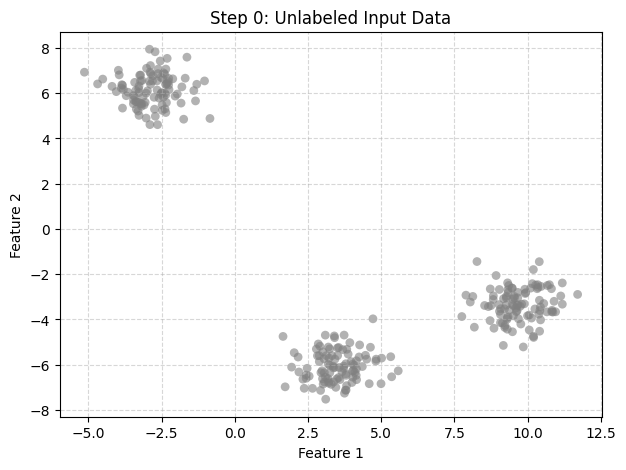

In [ ]:
# ==============================================================================
# Cell 1: Setup & Synthetic Data Generation
# ==============================================================================
# K-Means is an unsupervised clustering algorithm designed to group unlabeled
# data points into K distinct clusters based on feature similarity (Euclidean distance).
#
# It operates via Expectation-Maximization:
# 1. Assignment Step (Expectation): Assign each point to the closest centroid.
# 2. Update Step (Maximization): Recompute centroids as the mean of assigned points.
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# Exploratory Data Analyis (EDA)
np.random.seed(30)

# Generate synthetic 2D data with 3 distinct clusters
X, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.75, random_state=56)

# Visualize the raw, unlabeled dataset
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c='gray', alpha=0.6, edgecolors='none', s=40)
plt.title("Step 0: Unlabeled Input Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
# ==============================================================================
# Cell 2: Step-by-Step Implementation of K-Means Functions
# ==============================================================================

def initialize_centroids(X, k):
    """
    Step 1: Random Initialization
    Randomly selects k unique observations from the dataset X to act as initial centroids.
    """
    random_indices = np.random.choice(X.shape[0], size=k, replace=False)
    return X[random_indices]

def assign_clusters(X, centroids):
    """
    Step 2: Assignment Step (Expectation)
    Computes Euclidean distance from each sample to every centroid:
        dist(x, c) = sqrt(sum((x_i - c_i)^2))
    Assigns each sample to the index of the nearest centroid.
    """
    # X[:, np.newaxis] shape: (N, 1, D)
    # centroids shape:        (K, D)
    # Broadcast subtraction:  (N, K, D)
    distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
    return np.argmin(distances, axis=1)

def update_centroids(X, labels, k):
    """
    Step 3: Update Step (Maximization)
    Calculates the new centroid positions as the arithmetic mean of all points
    assigned to each cluster.
    """
    new_centroids = np.zeros((k, X.shape[1]))
    for cluster_idx in range(k):
        cluster_points = X[labels == cluster_idx]
        if len(cluster_points) > 0:
            new_centroids[cluster_idx] = cluster_points.mean(axis=0)
        else:
            # Handle empty cluster edge case by re-initializing randomly
            new_centroids[cluster_idx] = X[np.random.choice(X.shape[0])]
    return new_centroids

def compute_inertia(X, centroids, labels):
    """
    Calculates Within-Cluster Sum of Squares (WCSS / Inertia):
        WCSS = sum(||x_i - centroid_j||^2)
    """
    wcss = 0.0
    for idx, point in enumerate(X):
        centroid = centroids[labels[idx]]
        wcss += np.sum((point - centroid) ** 2)
    return wcss

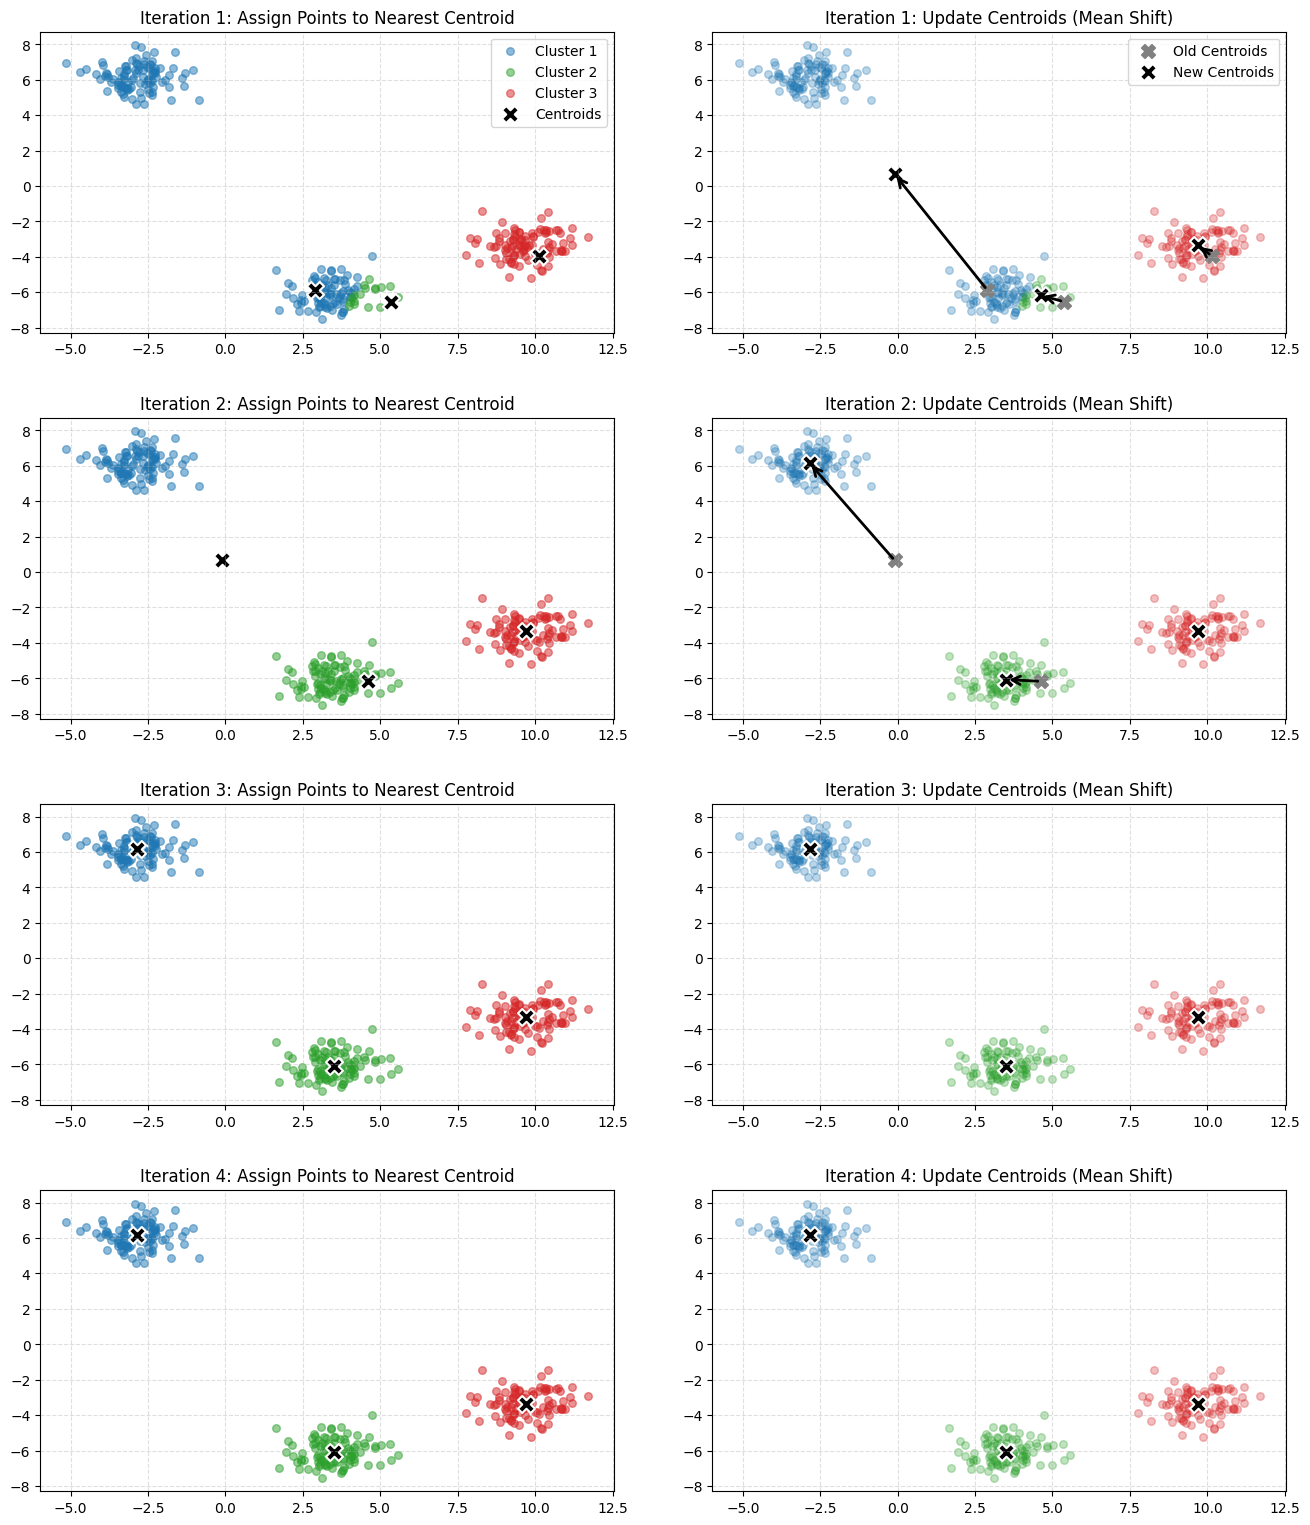

In [ ]:
# ==============================================================================
# Cell 3: Step-by-Step Visualizer Across Iterations
# ==============================================================================

k = 3
max_iterations = 4
colors = ['#1f77b4', '#2ca02c', '#d62728']

centroids = initialize_centroids(X, k)

fig, axes = plt.subplots(max_iterations, 2, figsize=(14, 4 * max_iterations))
fig.tight_layout(pad=4.0)

for it in range(max_iterations):
    # --- Substep A: Assign points to nearest centroid ---
    labels = assign_clusters(X, centroids)

    ax_assign = axes[it, 0]
    for cluster_idx in range(k):
        pts = X[labels == cluster_idx]
        ax_assign.scatter(pts[:, 0], pts[:, 1], c=colors[cluster_idx], alpha=0.5, s=30, label=f"Cluster {cluster_idx+1}")
    ax_assign.scatter(centroids[:, 0], centroids[:, 1], c='black', marker='X', s=150, edgecolors='white', linewidths=1.5, label='Centroids')
    ax_assign.set_title(f"Iteration {it + 1}: Assign Points to Nearest Centroid")
    ax_assign.grid(True, linestyle="--", alpha=0.4)
    if it == 0:
        ax_assign.legend(loc="upper right")

    # --- Substep B: Recompute centroid positions ---
    new_centroids = update_centroids(X, labels, k)

    ax_update = axes[it, 1]
    for cluster_idx in range(k):
        pts = X[labels == cluster_idx]
        ax_update.scatter(pts[:, 0], pts[:, 1], c=colors[cluster_idx], alpha=0.3, s=30)

    # Plot movement arrows from old centroids to new centroids
    for old_c, new_c in zip(centroids, new_centroids):
        ax_update.annotate(
            '', xy=new_c, xytext=old_c,
            arrowprops=dict(arrowstyle="->", color="black", lw=2, mutation_scale=15)
        )
    ax_update.scatter(centroids[:, 0], centroids[:, 1], c='gray', marker='X', s=100, label='Old Centroids')
    ax_update.scatter(new_centroids[:, 0], new_centroids[:, 1], c='black', marker='X', s=150, edgecolors='white', linewidths=1.5, label='New Centroids')
    ax_update.set_title(f"Iteration {it + 1}: Update Centroids (Mean Shift)")
    ax_update.grid(True, linestyle="--", alpha=0.4)
    if it == 0:
        ax_update.legend(loc="upper right")

    centroids = new_centroids

plt.show()

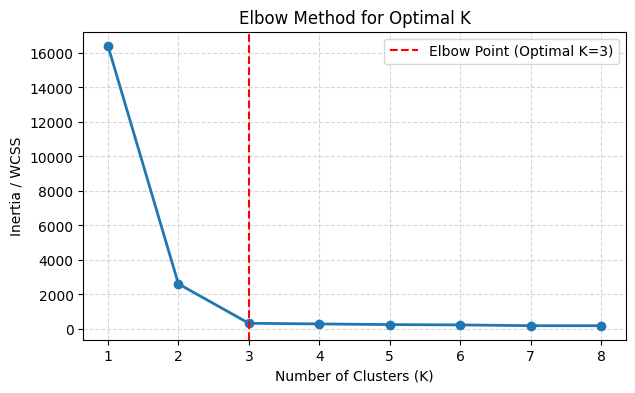

In [ ]:
# ==============================================================================
# Cell 4: Finding Optimal K (The Elbow Method)
# ==============================================================================
# In practice, K is often unknown beforehand. The Elbow Method computes the
# WCSS for a range of K values. The "elbow" point indicates diminishing returns
# from adding further clusters.
# ==============================================================================

wcss_values = []
k_range = range(1, 9)

for candidate_k in k_range:
    # Run a full convergence loop for each k
    c = initialize_centroids(X, candidate_k)
    for _ in range(20):
        lbls = assign_clusters(X, c)
        new_c = update_centroids(X, lbls, candidate_k)
        if np.allclose(c, new_c, atol=1e-4):
            break
        c = new_c
    wcss_values.append(compute_inertia(X, c, lbls))

plt.figure(figsize=(7, 4))
plt.plot(k_range, wcss_values, marker='o', linestyle='-', color='#1f77b4', linewidth=2)
plt.axvline(x=3, color='red', linestyle='--', label='Elbow Point (Optimal K=3)')
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia / WCSS")
plt.xticks(k_range)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()